# Walkthrough

The same steps as `python -m spl_predictor`, one at a time, with the intermediate tables on show.

**Question.** Using only past league results, how well can we predict where each club finishes next season?

In [1]:
import pandas as pd

from spl_predictor import plots
from spl_predictor.data import league_tables, load_final_table, load_matches, load_upcoming_teams
from spl_predictor.evaluate import paired_bootstrap, random_rank_mae, summarise, walk_forward
from spl_predictor.features import build_dataset
from spl_predictor.forecast import forecast_season, score_holdout, select_model
from spl_predictor.models import BASELINE, candidates

pd.set_option("display.float_format", "{:.2f}".format)

## 1. Data

Seven seasons of match results. Each row is one match.

In [2]:
matches = load_matches()
print(f"{len(matches):,} matches, {matches['season'].nunique()} seasons")
matches.head()

1,812 matches, 7 seasons


,season,date,home,away,home_goals,away_goals
0,2018-19,2018-08-30,Al-Ettifaq,Al-Raed,1,1
1,2018-19,2018-08-30,Al-Hazem,Al-Wehda,0,0
2,2018-19,2018-08-30,Ohod,Al-Nassr,1,2
3,2018-19,2018-08-31,Al-Qadsiah,Al-Fateh,0,0
4,2018-19,2018-08-31,Al-Shabab,Al-Ittihad,1,0


Matches are rolled up into a final table per season. The league grew from 16 to 18 clubs in 2023-24, so a season is 30 games before that and 34 after. Anything compared across seasons has to be per game.

In [3]:
tables = league_tables(matches)
tables.groupby("season").agg(clubs=("team", "size"), games_each=("played", "first"),
                             champion=("team", "first"), champion_points=("points", "first"))

,clubs,games_each,champion,champion_points
season,,,,
2018-19,16,30,Al-Nassr,70
2019-20,16,30,Al-Hilal,72
2020-21,16,30,Al-Hilal,61
2021-22,16,30,Al-Hilal,67
2022-23,16,30,Al-Ittihad,72
2023-24,18,34,Al-Hilal,96
2024-25,18,34,Al-Ittihad,83


## 2. Features

One row per club per season. Every feature is something known before that season's first match:

- `prev_ppg`, `prev_gd_pg`: points and goal difference per game last season
- `promoted`: 1 if the club was not in last season's table

`ppg` and `position` are the targets. The 2025-26 rows have features but no targets yet.

In [4]:
dataset = build_dataset(matches, load_upcoming_teams("2025-26"))
columns = ["season", "team", "promoted", "prev_ppg", "prev_gd_pg", "ppg", "position"]
dataset.loc[dataset["season"] == "2024-25", columns].sort_values("position").head(6)

,season,team,promoted,prev_ppg,prev_gd_pg,ppg,position
87,2024-25,Al-Ittihad,0,1.59,0.26,2.44,1.00
86,2024-25,Al-Hilal,0,2.82,2.29,2.21,2.00
90,2024-25,Al-Nassr,0,2.41,1.71,2.06,3.00
93,2024-25,Al-Qadsiah,1,0.85,-1.19,2.00,4.00
82,2024-25,Al-Ahli,0,1.91,0.94,1.97,5.00
96,2024-25,Al-Shabab,0,1.29,0.09,1.76,6.00


In [5]:
labelled = dataset.dropna(subset=["ppg"])
print(f"{len(labelled)} labelled rows across {labelled['season'].nunique()} seasons")

100 labelled rows across 6 seasons


That is the whole training set: about a hundred rows. Everything after this point is shaped by that number.

## 3. Backtest

Each model is trained on the seasons before a test season and predicts that season's table. Four test seasons, 68 club-seasons in total.

In [6]:
backtest = walk_forward(dataset, candidates())
summary = summarise(backtest)
summary[["test_mae", "season_sd", "train_mae", "gap", "within_3", "spearman"]]

,test_mae,season_sd,train_mae,gap,within_3,spearman
model,,,,,,
Last season,3.10,0.60,3.24,-0.14,0.68,0.64
Linear regression,2.68,0.77,2.77,-0.09,0.72,0.70
Random forest,3.25,0.92,1.62,1.63,0.65,0.59
Gradient boosting,3.44,0.87,1.45,1.99,0.59,0.56
v1: KNN on rank classes,2.96,0.51,2.69,0.26,0.68,0.65


In [7]:
print(f"A random table would be off by {random_rank_mae(16):.1f} places with 16 clubs, {random_rank_mae(18):.1f} with 18")

A random table would be off by 5.3 places with 16 clubs, 6.0 with 18


## 4. Is anything overfitting?

`gap` is the error on an unseen season minus the error on the seasons the model trained on. Gradient boosting and the random forest are far better on data they have already seen. Linear regression is not.

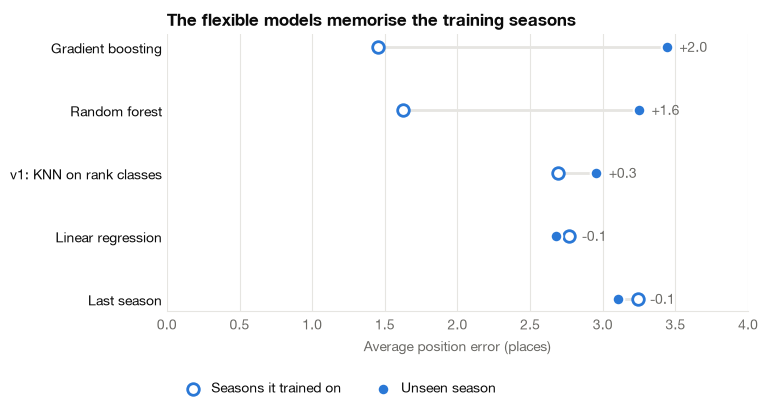

In [8]:
plots.overfitting_gap(summary);

## 5. Forecast 2025-26, then check it

The model is picked on the backtest alone. Only after the forecast exists do we load the real final table.

In [9]:
chosen = select_model(summary)
model = next(m for m in candidates() if m.name == chosen)
forecast = forecast_season(dataset, model, backtest)
print("Chosen model:", chosen)

final_table = load_final_table("2025-26")
forecast["position"] = forecast["team"].map(final_table.set_index("team")["position"])
forecast[["pred_position", "team", "pos_low", "pos_high", "p_title", "p_top4", "p_relegation", "position"]]

Chosen model: Linear regression


,pred_position,team,pos_low,pos_high,p_title,p_top4,p_relegation,position
0,1,Al-Ittihad,1.00,5.00,0.37,0.83,0.00,5
1,2,Al-Hilal,1.00,7.00,0.23,0.73,0.00,2
2,3,Al-Nassr,1.00,8.00,0.14,0.60,0.00,1
3,4,Al-Ahli,2.00,10.00,0.10,0.50,0.01,3
4,5,Al-Qadsiah,2.00,9.00,0.10,0.51,0.01,4
5,6,Al-Shabab,2.00,12.00,0.04,0.34,0.02,13
6,7,Al-Ettifaq,4.00,15.00,0.01,0.13,0.08,7
7,8,Al-Taawoun,5.00,16.00,0.01,0.09,0.11,6
8,9,Al-Kholood,6.00,17.00,0.00,0.04,0.20,14
9,10,Al-Fateh,6.00,17.00,0.00,0.04,0.21,11


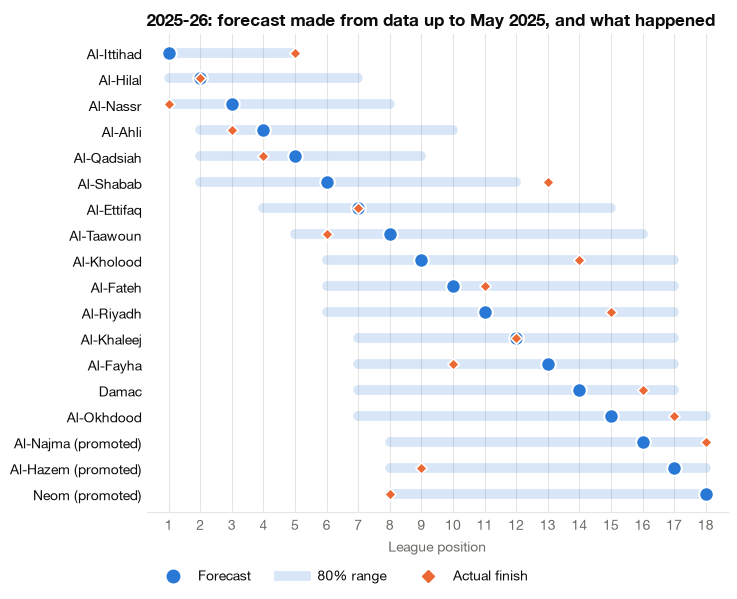

In [10]:
plots.forecast_vs_actual(forecast, final_table);

## 6. Every model on the season nobody tuned on

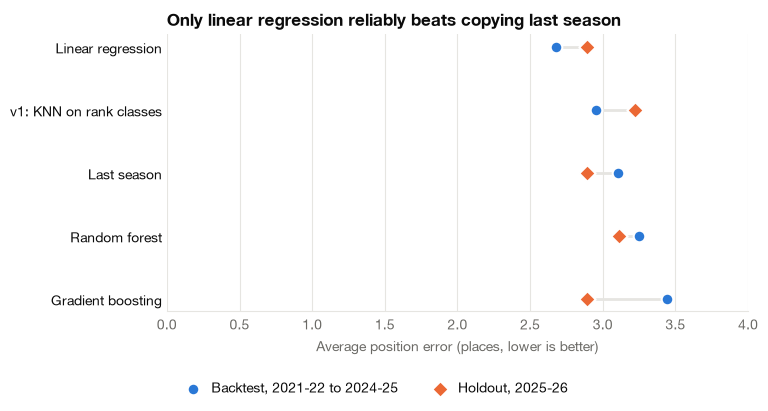

In [11]:
holdout = score_holdout(dataset, candidates(), final_table)
holdout_mae = holdout.groupby("model", sort=False)["abs_error"].mean()
plots.model_comparison(summary, holdout_mae);

Linear regression won the backtest; on 2025-26 it ties the baseline. Pooling all five out-of-sample seasons gives the fairest read on which models beat "same as last season":

In [12]:
scored = pd.concat([backtest[backtest["split"] == "test"], holdout.assign(season="2025-26")])
rows = {name: paired_bootstrap(scored, name, BASELINE) for name in summary.index if name != BASELINE}
pd.DataFrame(rows, index=["places vs baseline", "95% low", "95% high"]).T

,places vs baseline,95% low,95% high
Linear regression,-0.34,-0.59,-0.10
Random forest,0.16,-0.41,0.74
Gradient boosting,0.27,-0.34,0.88
v1: KNN on rank classes,-0.05,-0.42,0.33


Only linear regression has an interval that stays below zero, and the gain is about a third of a place. The original KNN classifier cannot be told apart from the baseline, and both tree models do worse.

## 7. What the line learned, and where the error comes from

In [13]:
fitted = model.fit(labelled)
print(dict(zip(model.features, fitted[-1].coef_.round(3))), "on standardised features")

errors = scored[scored["model"] == chosen]
print(errors.groupby("promoted")["abs_error"].agg(["mean", "size"]).rename(index={0: "established", 1: "promoted"}))
errors.nlargest(5, "abs_error")[["season", "team", "promoted", "pred_position", "position"]]

{'prev_ppg': np.float64(0.302), 'prev_gd_pg': np.float64(0.05), 'promoted': np.float64(0.044)} on standardised features
             mean  size
promoted               
established  2.24    70
promoted     4.81    16


,season,team,promoted,pred_position,position
707,2023-24,Al-Ahli,1,16.50,3.00
1163,2024-25,Al-Qadsiah,1,17.00,4.00
93,2021-22,Al-Ta'ee,1,15.00,6.00
35,2025-26,Neom,1,17.00,8.00
720,2023-24,Al-Ta'ee,0,8.50,17.00


Promoted clubs are a fifth of the rows and have about twice the error. The model knows nothing about a promoted side except that it is new. The four biggest misses are all promoted clubs, and three of them arrived with serious money: Al-Ahli in 2023-24, Al-Qadsiah in 2024-25 and Neom in 2025-26.